# II. Preparación y Análisis de Datos
# Capítulo 5 - Exploración de Datos con Descripción Estadística

<div style="border-top: 20px solid #b6effb; border-bottom: 20px solid #b6effb; background-color: #cff4fc; color: #055160">

En el presente caso de estudio se busca integrar y aplicar los conocimientos desarrollados previamente en programación, manipulación de datos y visualización, orientándolos hacia la construcción de uno de los procesos fundamentales dentro de la ciencia de datos: el **Análisis Exploratorio de Datos** (comúnmente conocido como EDA por sus siglas en inglés). Este tipo de análisis constituye una de las primeras etapas dentro de cualquier proyecto analítico o modelado predictivo, ya que permite comprender en profundidad la naturaleza de los datos antes de desarrollar modelos estadísticos o algoritmos de aprendizaje automático.

El propósito principal del **EDA** es examinar, resumir e interpretar la información disponible con el fin de identificar patrones, tendencias, anomalías, relaciones entre variables y posibles problemas de calidad en los datos. Más allá de simplemente observar tablas o calcular métricas básicas, el **EDA** busca generar una comprensión integral del comportamiento de las variables y de los fenómenos representados en el conjunto de datos. Esta etapa resulta esencial para formular hipótesis, detectar inconsistencias, definir estrategias de modelado y orientar adecuadamente la toma de decisiones basada en información.

En el contexto profesional, este análisis representa una habilidad indispensable para cualquier científico o analista de datos, ya que una comprensión insuficiente de los datos puede conducir a interpretaciones incorrectas, conclusiones erróneas o modelos poco confiables. Por esta razón, el **EDA** no debe entenderse únicamente como una etapa técnica, sino también como un proceso analítico e investigativo que combina herramientas estadísticas, pensamiento crítico y capacidad de interpretación.

Para desarrollar este tipo de análisis, tradicionalmente se emplean tres grandes herramientas complementarias que aportan mecanismos distintos para explorar y comprender la información desde diferentes perspectivas:

* **Estadística descriptiva**: corresponde al conjunto de técnicas orientadas al resumen y representación de datos mediante medidas estadísticas, con el objetivo de describir las características principales de una variable o conjunto de variables. Estas herramientas permiten por tanto obtener una visión inicial del comportamiento general de los datos y constituyen el punto de partida de cualquier **EDA**.

* **Estadística inferencial**: corresponde al área de la estadística enfocada en la formulación y validación de hipótesis a partir de la información disponible. A diferencia de la estadística descriptiva, que únicamente resume datos observados, la inferencia estadística busca extraer conclusiones más generales sobre estos datos, así como las relaciones y comportamientos subyacentes. Dentro de un **EDA**, este tipo de herramientas puede ayudar a evaluar asociaciones entre variables, diferencias entre grupos existentes y posibles patrones estadísticamente relevantes en el contexto.

* **Visualización de datos**: representa una de las herramientas más poderosas dentro del análisis exploratorio, ya que permite interpretar información compleja de manera intuitiva mediante gráficos y representaciones visuales equivalentes, haciendo posible identificar tendencias, valores atípicos, agrupamientos y relaciones que muchas veces no son evidentes únicamente con estadísticas numéricas. En consecuencia, la visualización complementa y fortalece tanto la estadística descriptiva como la inferencial, facilitando además la comunicación efectiva de hallazgos.

Durante el desarrollo de este caso de estudio, vamos a aplicar nuestros conocimientos de estadística descriptiva y visualización con librerías ya conocidas como **Pandas** y **Matplotlib**. Con esto, seremos capaces de construir un flujo básico de trabajo analítico similar al utilizado en proyectos reales de ciencia de datos y analítica de negocios, permitiéndote desarrollar no solamente habilidades técnicas relacionadas con programación y estadística aplicada, sino también capacidades analíticas fundamentales para interpretar información, formular preguntas relevantes y generar conocimiento útil a partir de los datos disponibles.

</div>

## Entendimiento del contexto

El Banco Mundial es un organismo multinacional cuyo propósito es el brindar asistencia económica y financiera a sus estados asociados. Entre los servicios que ofrece se encuentra la de generar y publicar diversos indicadores macroeconómicos, sociales, demográficos y ambientales que permiten estudiar y contrastar la situación multidimensional entre países a través de los años. Si es de tu interés, puedes acceder a todo su catálogo de información en este [repositorio](https://data.worldbank.org/).

Un dato importante para que tengas en cuenta es que a nivel mundial se reconocen oficialmente poco más de 200 estados, de los cuales algunos proveen de información al Banco Mundial (estados miembro de la entidad) y otros no lo hacen. La entidad, si le es posible, estima mediante modelos econométricos algunos de estos indicadores faltantes, aunque en muchos casos ha preferido dejar en blanco estos datos a fin de garantizar la integridad original de la información. 

Visto este escenario, el Banco Mundial te ha contratado para que realices un análisis respecto al comportamiento de la Variación del Producto Interno Bruto (PIB) entre los años 2000 y 2023. En concreto, esta entidad quiere que le asistas contestando las siguientes preguntas clave para una mayor comprensión de esta métrica:

* ¿Cuál ha sido el comportamiento de este indicador a partir del cambio de siglo?
* ¿Qué variables inciden principalmente en los cambios a nivel de este indicador?
* ¿Qué tan probable es que un país tenga una recesión o reducción del PIB en un año cualquiera?
* ¿Existen diferencias significativas en el crecimiento de países de "bajo desarrollo" frente a países de "alto desarrollo"?

## Entendimiento de los datos

Como punto de partida, vale que importes las librerías que vas a utilizar. Vamos a importar además una librería llamada **Warnings** con el siguiente código:

```py
import warnings
warnings.filterwarnings("ignore")
```

Hacer esto evitará que surjan mensajes de advertencia o informativos que dificulten la lectura de nuestro notebook.

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

Carga ahora los datos de los 5 archivos siguientes: 

* [**cat_codpais3.csv**](https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/cat_codpais3.csv)
* [**wb_ahorro.csv**](https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/wb_ahorro.csv)
* [**wb_crecimpib.csv**](https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/wb_crecimpib.csv)
* [**wb_crecimpob.csv**](https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/wb_crecimpob.csv)
* [**wb_poburbana.csv**](https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/wb_poburbana.csv)

Estos datos son los que te ha compartido el Banco Mundial para que bases tu análisis a partir de allí.

In [2]:
# Cargar cat_codpais3
cat_pais = pd.read_csv("https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/cat_codpais3.csv")

# Cargar wb_ahorro
df_ahorro = pd.read_csv("https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/wb_ahorro.csv")

# Cargar wb_crecimpib
df_pib = pd.read_csv("https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/wb_crecimpib.csv")

# Cargar wb_crecimpob
df_poblacion = pd.read_csv("https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/wb_crecimpob.csv")

# Cargar wb_poburbana
df_urbana = pd.read_csv("https://raw.githubusercontent.com/jsaraujo5081/material_curso_data_science/refs/heads/main/datasets/wb_poburbana.csv")

Las 5 tablas contienen información asociada a indicadores macroeconómicos por país de acuerdo al siguiente detalle:

* **cat_codpais3**: [214 filas, 2 columnas] Catálogo que contiene el nombre de cada país y sus siglas *Alpha-3* de acuerdo a la normativa ISO.
* **wb_ahorro**: [265, 25] Series anuales 2000 - 2023 por país respecto al porcentaje promedio de ahorro que mantienen los habitantes como porcentaje de su ingreso. 
* **wb_crecimpib**: [265, 25] Series anuales 2000 - 2023 por país respecto a la tasa de variación del PIB. 
* **wb_crecimpob**: [265, 25] Series anuales 2000 - 2023 por país respecto a la tasa de variación de la población.
* **wb_poburbana**: [265, 25] Series anuales 2000 - 2023 por país respecto al porcentaje de la población que reside en áreas urbanas.

Con el objetivo de una exploración de datos y diagnóstico más eficientes, crea una función que para cualquier dataset te permita mirar: 

* La estructura general del dataset mediante el método `info`.
* Una muestra aleatoria de 5 filas del dataset con el método `sample` en la que además se presenten solamente las primeras 6 columnas del dataset.
* Un conteo de los duplicados existentes del dataset usando el método `duplicated`.

In [ ]:
def fun_diagnostico (df):
    print("ESTRUCTURA GENERAL DE LA TABLA:")
    df.info()
    print()
    print("MUESTRA DE LOS DATOS: ")
    print(df.sample(5).iloc[:,:6])
    print()
    print(f"FILAS DUPLICADAS: {df.duplicated().sum()}")

Aplica la función creada en cada uno de los datasets para conocerlos en mayor detalle.

In [4]:
# Explorar cat_pais
fun_diagnostico(cat_pais)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   country_code  214 non-null    object
 1   country_name  214 non-null    object
dtypes: object(2)
memory usage: 3.5+ KB
None

MUESTRA DE LOS DATOS: 
    country_code country_name
88           IRL      Irlanda
10           AUS    Australia
73           GMB       Gambia
147          PAK     Pakistan
198          URY      Uruguay

FILAS DUPLICADAS: 0


In [5]:
# Explorar df_ahorro
fun_diagnostico(df_ahorro)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 25 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Code  265 non-null    object 
 1   2000          161 non-null    float64
 2   2001          160 non-null    float64
 3   2002          167 non-null    float64
 4   2003          169 non-null    float64
 5   2004          169 non-null    float64
 6   2005          187 non-null    float64
 7   2006          190 non-null    float64
 8   2007          195 non-null    float64
 9   2008          196 non-null    float64
 10  2009          198 non-null    float64
 11  2010          200 non-null    float64
 12  2011          201 non-null    float64
 13  2012          204 non-null    float64
 14  2013          204 non-null    float64
 15  2014          206 non-null    float64
 16  2015          207 non-null    float64
 17  2016          205 non-null    float64
 18

In [6]:
# Explorar df_pib
fun_diagnostico(df_pib)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 25 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Code  265 non-null    object 
 1   2000          246 non-null    float64
 2   2001          247 non-null    float64
 3   2002          247 non-null    float64
 4   2003          251 non-null    float64
 5   2004          251 non-null    float64
 6   2005          251 non-null    float64
 7   2006          251 non-null    float64
 8   2007          252 non-null    float64
 9   2008          252 non-null    float64
 10  2009          255 non-null    float64
 11  2010          255 non-null    float64
 12  2011          255 non-null    float64
 13  2012          255 non-null    float64
 14  2013          255 non-null    float64
 15  2014          256 non-null    float64
 16  2015          256 non-null    float64
 17  2016          255 non-null    float64
 18

In [7]:
# Explorar df_poblacion
fun_diagnostico(df_poblacion)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 25 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Code  265 non-null    object 
 1   2000          264 non-null    float64
 2   2001          264 non-null    float64
 3   2002          264 non-null    float64
 4   2003          264 non-null    float64
 5   2004          264 non-null    float64
 6   2005          264 non-null    float64
 7   2006          264 non-null    float64
 8   2007          264 non-null    float64
 9   2008          264 non-null    float64
 10  2009          264 non-null    float64
 11  2010          264 non-null    float64
 12  2011          264 non-null    float64
 13  2012          264 non-null    float64
 14  2013          264 non-null    float64
 15  2014          264 non-null    float64
 16  2015          264 non-null    float64
 17  2016          264 non-null    float64
 18

In [8]:
# Explorar df_urbana
fun_diagnostico(df_urbana)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 25 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Code  265 non-null    object 
 1   2000          262 non-null    float64
 2   2001          262 non-null    float64
 3   2002          262 non-null    float64
 4   2003          262 non-null    float64
 5   2004          262 non-null    float64
 6   2005          262 non-null    float64
 7   2006          262 non-null    float64
 8   2007          262 non-null    float64
 9   2008          262 non-null    float64
 10  2009          262 non-null    float64
 11  2010          262 non-null    float64
 12  2011          262 non-null    float64
 13  2012          262 non-null    float64
 14  2013          262 non-null    float64
 15  2014          262 non-null    float64
 16  2015          262 non-null    float64
 17  2016          262 non-null    float64
 18

Excluyendo a la tabla con el catálogo de países, podrás notar que el resto de datasets tiene una estructura particular en la que cada año está representado por una columna distinta. Esto puede resultar complejo y para comprobarlo hagamos un experimento: filtra los datos de variación del PIB de Estados Unidos (código de país: USA) de los años 2013 a 2019, y guarda el resultado en una variable `pib_usa`.

In [9]:
pib_usa = df_pib.query("`Country Code` == 'USA'").loc[:,"2013":"2019"]
print(pib_usa)

        2013     2014     2015      2016      2017      2018      2019
251  2.11783  2.52382  2.94555  1.819451  2.457622  2.966505  2.467038


Intenta ahora graficar estos datos con el método `plot` como usualmente lo has venido haciendo. No te preocupes por aspectos de formato pues solamente es un ejemplo ilustrativo.

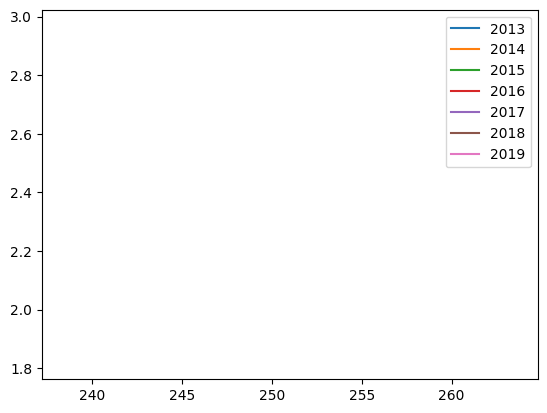

In [10]:
pib_usa.plot()
plt.show()

En cuanto a estos resultados notemos dos puntos importantes: 

* Por una parte, el filtrado no es tan natural como usualmente lo hacemos. De hecho resultaría imposible en este punto responder esta pregunta usando el método `query` para filtrar los años solicitados. 
* Además, no es posible graficar de forma directa y sencilla con el método `plot` como ya lo hemos venido haciendo. Requeriríamos de una transformación adicional de la información para que funcione adecuadamente. 

Esto se explica porque el dataset que muestra información de variación en el PIB es **ANCHO**. Un dataset ancho es aquel en que cada fila representa a una única entidad (en este caso un país) que no se repite en otras filas. Su utilidad radica en que esta presentación de datos es fácil de interpretar por usuarios "no analíticos", justamente porque se puede acceder a la totalidad información de cada entidad de forma rápida y directa en un solo registro.

Sin embargo, para usuarios "analíticos" como nosotros esta presentación no es adecuada, pues nosotros queremos tablas **LARGAS**. En una tabla larga cada fila representa una observación (o lo que es lo mismo un dato) con sus diferentes variables y particularidades, facilitando en consecuencia la manipulación y visualización de información.

<div class="alert alert-info">

Para una discusión más académica y conceptual respecto a la importancia de tablas *largas* en el análisis de datos y la estadística te sugiero que revises este <a href="https://www.jstatsoft.org/article/view/v059i10">artículo</a> de Hadley Wickham publicado en el Journal of Statistical Software de Agosto de 2014.   

</div>

Visto todo esto, define tu plan de acción para preparar estos datos.

<div class="alert alert-success">

**PLAN DE ACCIÓN PARA PREPARACIÓN DE DATOS**

| Problema detectado | Acción planificada |
| ---- | ---- |
| Las tablas de indicadores macroeconómicos presentan un formato *ancho*. | Transformar su presentación para que sean tablas *largas* que permitan su uso analítico. |
| Los nombres de las columnas en estas tablas presentan mayúsculas y espacios. | Cambiar los nombres de las columnas  a formato *snake_case*. |
| Estas tablas además presentan valores ausentes que dado el contexto, puede que respondan a diferentes situaciones dependiendo del país al cual se corresponden (i.e países que no remiten información al Banco Mundial o países que en unos pocos años no remitieron datos). | Tomar una decisión sobre cómo tratarlos una vez que sea posible filtrar esta información fácilmente en tablas largas. |
| Existen 5 datasets distintos, todos con información relevante. | Unir todos los datasets en una única tabla consolidada a fin de no depender de diferentes fuentes durante el análisis. |

</div>

## Preparación de datos

Vamos a empezar con la tabla que tiene información de la variación del PIB. Transforma la presentación *ancha* de este dataset a una de tipo *largo*, aplicando el método `melt` de tal forma que se genere un nuevo dataframe de 3 columnas: Country Code, year y value.

In [11]:
# Transformar a presentacion larga con metodo melt
df_pib = df_pib.melt(
    id_vars = "Country Code",  
    var_name = "year", 
    value_name = "value"
)
fun_diagnostico(df_pib)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6360 entries, 0 to 6359
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Code  6360 non-null   object 
 1   year          6360 non-null   object 
 2   value         6051 non-null   float64
dtypes: float64(1), object(2)
memory usage: 149.2+ KB
None

MUESTRA DE LOS DATOS: 
     Country Code  year     value
6038          SGP  2022  3.838077
3717          ARB  2014  2.383705
6031          ROU  2022  4.107027
4486          TZA  2016  6.867116
4487          UGA  2016  4.781000

FILAS DUPLICADAS: 0


<div class="alert alert-info">

Se debe señalar que igualmente se puede utilizar también la función `wide_to_long` tal y como se muestra a continuación:

```py
df_pib = pd.wide_to_long(
    df_pib,
    stubnames = "",
    i = "Country Code",
    j = "year" 
).reset_index()
df_pib = df_pib.rename(columns = {"":"value"})
```
Te sugiero que investigues sobre su funcionalidad en la <a href="https://pandas.pydata.org/docs/reference/api/pandas.wide_to_long.html">documentación</a> de **Pandas**.  

</div>

Ajusta los nombres de las columnas para que estos sigan el formato *snake_case*.

In [12]:
df_pib.columns = [x.lower().replace(" ","_") for x in df_pib.columns]
fun_diagnostico(df_pib)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6360 entries, 0 to 6359
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  6360 non-null   object 
 1   year          6360 non-null   object 
 2   value         6051 non-null   float64
dtypes: float64(1), object(2)
memory usage: 149.2+ KB
None

MUESTRA DE LOS DATOS: 
     country_code  year      value
5517          SSF  2020  -1.966895
2004          MCO  2007  14.438636
2360          TSA  2008   3.298105
253           VCT  2000   1.639032
4822          CYM  2018   4.267266

FILAS DUPLICADAS: 0


Ya podemos diagnosticar de mejor manera los valores perdidos con esta tabla *larga*. Identifica diferentes tipologías de países en función de cuántos valores ausentes tengan replicando el siguiente código:

```py
casos_perdidos = (
    df_pib[df_pib["value"].isna()]
    .groupby("country_code")
    .agg(casos = ("country_code","count"))
    .sort_values(by = "casos", ascending = False)
)
casos_perdidos.plot(
    kind = "bar",
    figsize = [7,4],
    legend = None,
    ylabel = "Años perdidos",
    xlabel = "Código de pais"
)
plt.grid(axis = "y")
plt.show()
```

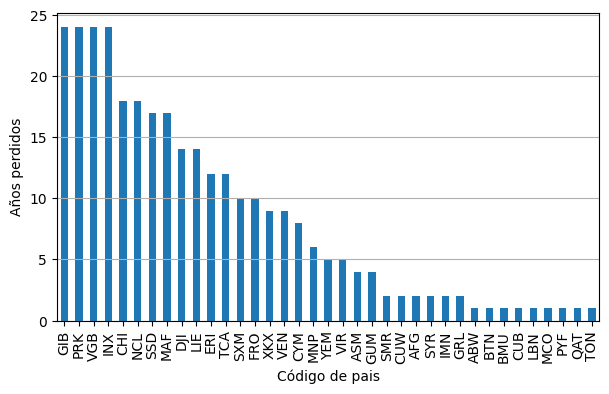

In [13]:
casos_perdidos = (
    df_pib[df_pib["value"].isna()]
    .groupby("country_code")
    .agg(casos = ("country_code","count"))
    .sort_values(by = "casos", ascending = False)
)
casos_perdidos.plot(
    kind = "bar",
    figsize = [7,4],
    legend = None,
    ylabel = "Años perdidos",
    xlabel = "Código de pais"
)
plt.grid(axis = "y")
plt.show()

Visto esto, podríamos dividir a los países en 2 grupos en base a sus valores ausentes y aplicando de forma simplificada la Ley de Pareto:

* Aquellos que tienen 5 o menos años con valores perdidos.
* El resto que posee más de 5 años con valores perdidos.

Para el último caso que correspondería a los países con pocos o ningún dato relevante, elimina todos estos registros pues su información está limitada pudiendo distorsionar los análisis.

In [14]:
paises_eliminar = list(casos_perdidos.query('casos > 5').index)
df_pib = df_pib[~df_pib["country_code"].isin(paises_eliminar)]
fun_diagnostico(df_pib)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
Index: 5928 entries, 0 to 6359
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  5928 non-null   object 
 1   year          5928 non-null   object 
 2   value         5889 non-null   float64
dtypes: float64(1), object(2)
memory usage: 185.2+ KB
None

MUESTRA DE LOS DATOS: 
     country_code  year     value
3795          GIN  2014  3.696553
153           MEA  2000  6.764848
1074          AUT  2004  2.735120
731           ROU  2002  5.702992
336           EST  2001  6.003674

FILAS DUPLICADAS: 0


Para el primer caso, en donde existen muchos datos relevantes, aplica una imputación por el valor mediano de dicho país considerando que esto no alterará significativamente los resultados de los análisis.

In [15]:
# Obtener la mediana por pais
med_por_pais = (
    df_pib
    .groupby("country_code")
    .agg(med = ("value","median"))
    .reset_index()
)

# Incluir de forma temporal la mediana en el dataset
df_pib = df_pib.merge(
    med_por_pais,
    on = "country_code"
)

# Imputar la mediana en los casos perdidos correspondientes
df_pib["value"] = df_pib["value"].fillna(df_pib["med"])

# Quitar columna de mediana 
df_pib = df_pib.drop(columns = "med")
fun_diagnostico(df_pib)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5928 entries, 0 to 5927
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  5928 non-null   object 
 1   year          5928 non-null   object 
 2   value         5928 non-null   float64
dtypes: float64(1), object(2)
memory usage: 139.1+ KB
None

MUESTRA DE LOS DATOS: 
     country_code  year     value
5778          IBT  2023  4.363221
5526          HPC  2022  4.796361
5326          MAR  2021  8.020984
4687          VUT  2018  2.900230
1545          ECU  2006  4.341132

FILAS DUPLICADAS: 0


<div class="alert alert-info">

La decisión acerca del tratamiento de valores perdidos no es una regla fija e inmutable, siempre tiene que hacerse tomando en consideración tres criterios fundamentales:

* El contexto del caso de estudio que se esté realizando.
* La cantidad de valores perdidos en relación al total de datos existentes.
* La lógica y el pragmatismo del analista.

</div>

Concluye ejecutando los siguientes procedimientos de limpieza adicionales, los cuales han surgido de los procedimientos realizados en los pasos previos:

* Cambiar el tipo de variable de year a entero.
* Cambia el nombre de la columna value a algo más coherente con el contexto como *var_pib*.

In [16]:
# Cambiar el tipo de variable de year
df_pib["year"] = df_pib["year"].astype(int)

# Cambiar el nombre de la columna "value"
df_pib = df_pib.rename(columns={"value":"var_pib"})
fun_diagnostico(df_pib)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5928 entries, 0 to 5927
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  5928 non-null   object 
 1   year          5928 non-null   int64  
 2   var_pib       5928 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 139.1+ KB
None

MUESTRA DE LOS DATOS: 
     country_code  year   var_pib
4385          PST  2017  2.465087
654           NAC  2002  1.801247
1921          SAS  2007  7.139166
2628          MWI  2010  6.874066
993           ALB  2004  5.514668

FILAS DUPLICADAS: 0


Ahora bien, considera que esta limpieza debe repetirse exactamente igual en los otros datasets con indicadores macroeconómicos. Por lo tanto, automatiza el proceso mediante la definición de una función que reciba como entradas una tabla y un nombre de variable adecuado, y devuelva un dataframe completamente limpio siguiendo todos los pasos realizados en los pasos precedentes.

In [17]:
# Crear una funcion que permita automatizar el procedimiento de limpieza
def fun_procesamiento (df, nombre_col):
    
    # Transformar a tabla larga
    df = df.melt(
        id_vars = "Country Code", 
        var_name = "year", 
        value_name = "value"
    )

    # Ajustar nombres de columnas a snake_case
    df.columns = [x.lower().replace(" ","_") for x in df.columns]

    # Suprimir paises con muchos valores perdidos
    casos_perdidos = (
        df[df["value"].isna()]
        .groupby("country_code")
        .agg(casos = ("country_code","count"))
        .sort_values(by = "casos",ascending=False)
    )
    paises_eliminar = list(casos_perdidos.query('casos > 5').index) 
    df = df[~df['country_code'].isin(paises_eliminar)]

    # Imputar mediana a valores perdidos de resto de paises
    med_por_pais = (
        df
        .groupby('country_code')
        .agg(med = ("value","median"))
        .reset_index()
    )    
    df = df.merge(
        med_por_pais,
        on = "country_code",
    )
    df["value"] = df["value"].fillna(df["med"])
    df = df.drop(columns="med")
    
    # Convertir columna year a entero
    df['year'] = df['year'].astype(int)

    # Cambiar nombre de columna del indicador
    df = df.rename(columns={"value":nombre_col})

    return df

Con esta función realiza la limpieza de las demás tablas con indicadores macroeconómicos.

In [18]:
# Aplicar funcion en df_ahorro
df_ahorro = fun_procesamiento(df_ahorro, "ahorro")
fun_diagnostico(df_ahorro)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3936 entries, 0 to 3935
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  3936 non-null   object 
 1   year          3936 non-null   int64  
 2   ahorro        3936 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 92.4+ KB
None

MUESTRA DE LOS DATOS: 
     country_code  year     ahorro
2019          FJI  2012  15.830081
3155          EAP  2019  41.519388
2783          USA  2016  18.558693
2536          JOR  2015  16.003860
1802          VUT  2010  17.796440

FILAS DUPLICADAS: 0


In [19]:
# Aplicar funcion en df_poblacion
df_poblacion = fun_procesamiento(df_poblacion, "var_pob")
fun_diagnostico(df_poblacion)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6336 entries, 0 to 6335
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  6336 non-null   object 
 1   year          6336 non-null   int64  
 2   var_pob       6336 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 148.6+ KB
None

MUESTRA DE LOS DATOS: 
     country_code  year   var_pob
3229          EAP  2012  0.856579
3946          USA  2014  0.733362
5090          FCS  2019  2.250694
3335          MWI  2012  2.832566
4453          TEA  2016  0.754938

FILAS DUPLICADAS: 0


In [20]:
# Aplicar funcion en df_urbana
df_urbana = fun_procesamiento(df_urbana, "pct_urbana")
fun_diagnostico(df_urbana)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6288 entries, 0 to 6287
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  6288 non-null   object 
 1   year          6288 non-null   int64  
 2   pct_urbana    6288 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 147.5+ KB
None

MUESTRA DE LOS DATOS: 
     country_code  year  pct_urbana
3410          AGO  2013      62.002
44            COG  2000      58.695
1716          LVA  2006      67.967
1730          MMR  2006      28.132
1648          FJI  2006      50.264

FILAS DUPLICADAS: 0


Consolida la información de estos 4 datasets de indicadores macroeconómicos en una sola tabla de tal forma que se garantice que no existan nuevos valores ausentes en ningún indicador.

In [21]:
df_consolidado = (
    df_pib
    .merge(
        df_ahorro,
        on = ["country_code", "year"],
        how = "inner"
    )
    .merge(
        df_poblacion,
        on = ["country_code", "year"],
        how = "inner"
    )
    .merge(
        df_urbana,
        on = ["country_code", "year"],
        how = "inner"
    )
)
fun_diagnostico(df_consolidado)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3936 entries, 0 to 3935
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  3936 non-null   object 
 1   year          3936 non-null   int64  
 2   var_pib       3936 non-null   float64
 3   ahorro        3936 non-null   float64
 4   var_pob       3936 non-null   float64
 5   pct_urbana    3936 non-null   float64
dtypes: float64(4), int64(1), object(1)
memory usage: 184.6+ KB
None

MUESTRA DE LOS DATOS: 
     country_code  year   var_pib     ahorro   var_pob  pct_urbana
257           LUX  2001  3.074355  30.461156  1.190456   84.843000
2364          IBT  2014  4.846309  32.975999  1.330595   48.202252
1786          TGO  2010  5.854353  10.931159  2.671317   37.533000
2361          HTI  2014  2.888773  11.607218  1.465968   51.444000
2875          LCN  2017  1.889825  16.653877  0.976271   80.414393

FILAS DUPLICADAS: 0


Incorpora ahora en esta información el nombre de los paises garantizando nuevamente que no existan valores perdidos en ninguna columna.

In [22]:
df_consolidado = cat_pais.merge(
    df_consolidado,
    on = "country_code",
    how = "inner"
)
fun_diagnostico(df_consolidado)

ESTRUCTURA GENERAL DE LA TABLA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3144 entries, 0 to 3143
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   country_code  3144 non-null   object 
 1   country_name  3144 non-null   object 
 2   year          3144 non-null   int64  
 3   var_pib       3144 non-null   float64
 4   ahorro        3144 non-null   float64
 5   var_pob       3144 non-null   float64
 6   pct_urbana    3144 non-null   float64
dtypes: float64(4), int64(1), object(2)
memory usage: 172.1+ KB
None

MUESTRA DE LOS DATOS: 
     country_code    country_name  year   var_pib     ahorro   var_pob
2150          NIC       Nicaragua  2014  4.785847  20.631387  1.448705
3029          USA  Estados Unidos  2005  3.483550  18.122458  0.921713
1096          GEO         Georgia  2016  3.450215  16.703913  0.059817
941           ESP          Espana  2005  3.652084  22.123067  1.689349
309           BGR        Bu

## Análisis exploratorio de datos

Como ya se mencionó, el **EDA** busca estudiar el comportamiento de indicadores concretos mediante la aplicación de técnicas estadísticas y visualización. En este sentido conviene recordar que la principal métrica de interés en el contexto de este caso es la **variación del pib**, ante la cual se han planteado las siguientes preguntas:

* ¿Cuál ha sido el comportamiento de este indicador en el nuevo siglo?
* ¿Qué variables inciden principalmente en los cambios a nivel de este indicador?
* ¿Qué tan probable es que un país tenga una recesión en un año cualquiera?
* ¿Existen diferencias significativas en el crecimiento de países de "bajo desarrollo" frente a países de "alto desarrollo"?

Procedamos entonces contestando a las mismas una a una.

### ¿Cuál ha sido el comportamiento de la variación en el PIB mundial en el nuevo siglo?

Estudia la distribución del indicador mediante un resumen estadístico. Recuerda que la distribución de una variable hace referencia a sus siguientes características fundamentales:

* Su nivel de **centralidad**.

* Su grado de **dispersión** o variabilidad.

* La existencia de **valores atípicos**.

* La existencia de **sesgos**.  

In [23]:
# Agregar informacion a nivel mundial
pib_mundial = (
    df_consolidado
    .groupby("year")
    .agg(var_pib = ("var_pib","mean"))
)

# Generar resumen estadistico
pib_mundial["var_pib"].describe().round(2)

count    24.00
mean      3.44
std       2.29
min      -4.77
25%       3.03
50%       3.57
75%       4.42
max       7.18
Name: var_pib, dtype: float64

En este resumen estadístico se evidencian distintas métricas que nos ayudan a comprender el comportamiento de la distribución de la variable. En concreto se nos muestra lo siguiente:

* La **media aritmética** (mean) y la **mediana** (50%) que constituyen medidas de *centralidad* de los datos al ser valores típicos de la variable.

* La **desviación estándar** (std) que mide la *dispersión* al representar la distancia promedio de cada observación respecto a su media aritmética.

* La existencia de *valores atípicos* no se visualiza directamente pero podría inferirse mediante operaciones simples con algunos de estos resultados. Notemos que la diferencia entre el valor mínimo (min) y el primer cuartil (25%) es de 7.8 unidades. Y la diferencia entre el tercer cuartil (75%) y el máximo (max) es de 2.76; dado que la primera diferencia es mayor que la segunda, existiría evidencia que existen valores atípicos de magnitud pequeña.

* En cuanto al *sesgo* igualmente no se tiene una representación directa, pero igualmente hay mecanismos simples de inferencia. Por ejemplo, notemos que la diferencia entre el primer cuartil y la mediana es de 0.54, mientras que la resta entre mediana y tercer cuartil da un valor de 0.85. Dado que este último resultado es mayor, se cuenta con evidencia para indicar que existe un sesgo positivo (hacia valores altos).

Si bien las medidas de centralidad son relativamente sencillas en cuanto a su interpretación, el resto resultan un tanto más complejas y por ello vamos a mostrar algunas formas distintas de visualizarlas y comprenderlas mejor.

Para empezar con la dispersión y la desviación estándar, calcula en primera instancia el denominado **coeficiente de variación** dividiendo la mencionada desviación estándar por la media aritmética de la variable estudiada.

In [24]:
cv = pib_mundial["var_pib"].std() / pib_mundial["var_pib"].mean()
print(f"Coeficiente de variación: {cv:.1%}")

Coeficiente de variación: 66.6%


Este resultado nos dice que en promedio los datos se encuentran a una distancia de aproximadamente 67% de su valor central. Aun cuando no existe una regla generalmente aceptada, si el coeficiente de variación es menor a 50% se habla de una dispersión baja, si se encuentra entre 50% y 100% se considera una dispersión moderada, y sobre el 100% la dispersión sería alta.

Para complementar lo anterior, utiliza ahora el criterio *3-sigma* para establecer el rango de comportamiento esperado de la variación del PIB. Recuerda que este criterio establece que con un 99% de confianza, una variable $x$ se encontrará en el rango

$$ [\bar x - 3\sigma_x,\; \bar x + 3\sigma_x] $$

donde $\bar x$ corresponde a la media de la variable, y $\sigma_x$ a su desviación estándar.

In [25]:
lim_inf = pib_mundial["var_pib"].mean() - 3 * pib_mundial["var_pib"].std()
lim_sup = pib_mundial["var_pib"].mean() + 3 * pib_mundial["var_pib"].std()
print(f"Con un 99% de confianza, la variación mundial del PIB estará entre {lim_inf:.1f}% y {lim_sup:.1f}%.")

Con un 99% de confianza, la variación mundial del PIB estará entre -3.4% y 10.3%.


Si bien el rango encontrado es por decirlo de alguna manera "pequeño", el hecho que la variación en el PIB mundial pueda encontrarse entre un porcentaje negativo y uno positivo (y significativo) complementa el argumento que existe al menos cierto grado de volatilidad en esta variable. 

Continuemos ahora con el estudio de la distribución incorporando gráficos descriptivos. Para empezar, crea un diagrama de cajón con bigotes utilizando el método `plot` con el argumento `kind = "box"`.

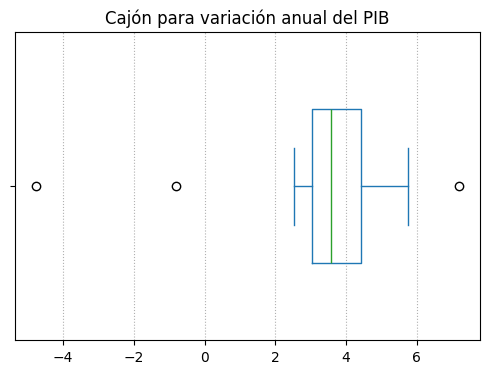

In [26]:
pib_mundial.plot(
    kind = "box",
    y = "var_pib",
    vert = False,
    widths = 0.5,
    figsize = [6, 4],
    title = "Cajón para variación anual del PIB"
)
plt.grid(axis = "x", linestyle = ":")
plt.yticks(ticks = [1], labels = [""])
plt.show()

En esta visualización es posible apreciar lo siguiente:

* El "cajón" representa la ubicación del 50% de los datos centrales de la variable estudiada. En este sentido, su límite inferior corresponde al primer cuartil y su limite superior al tercero.

* La línea dentro del cajón se corresponde con la mediana de los datos.

* Los "bigotes" muestran las ubicaciones de aquellos datos considerados "bajos" o "altos" aunque no por ello atípicos.

* Los "puntos" son aquellos casos considerados atípicos.   

Dado que se observan valores atípicos que dificultan la visualización de la distribución, repite el gráfico excluyendo los mismos con el argumento `showfliers = False`.

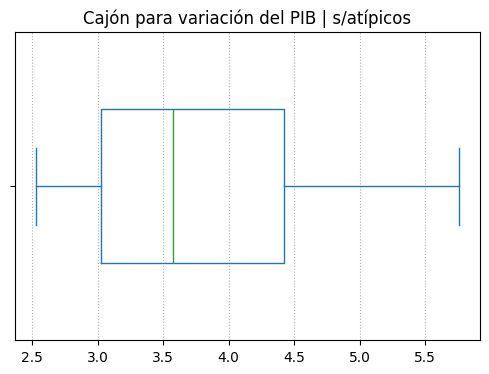

In [27]:
pib_mundial.plot(
    kind = "box",
    y = "var_pib",
    vert = False,
    widths = 0.5,
    figsize = [6, 4],
    title = "Cajón para variación del PIB | s/atípicos",
    showfliers = False
)
plt.grid(axis = "x", linestyle = ":")
plt.yticks(ticks = [1], labels = [""])
plt.show()

Vale señalar que un valor se considera atípico si el mismo NO se encuentra dentro del intervalo 

$$ \left[ Q_1 - 1.5R_Q,\; Q_3 + 1.5R_Q\right]$$

donde $Q_1$ es el primer cuartil, $Q_3$ el tercero, y $R_Q$ es el rango intercuartil definido por $R_Q = Q_3 - Q_1$.

Ahora bien, si no consideramos los valores atípicos podrás notar que existe un grado de desbalanceo en el diagrama realizado, tal que la parte derecha es más "larga" que la parte izquierda. Lo anterior no es otra cosa que el sesgo de la distribución.

Complementa ahora este resultado con un histograma tal que se cumpla con lo siguiente: 

* Excluye del dataset los casos atípicos aplicando la fórmula anterior.

* Utiliza en el gráfico un número de barras ($b$) pertinente con el método `bins`, para lo cual puedes utilizar la fórmula $b \approx \sqrt{n}$, donde $n$ es el número de observaciones no atípicas.

Si empleas el método `plot`, incluye el argumento `kind = "hist"`.

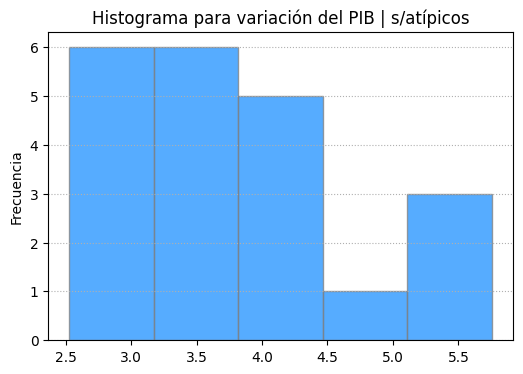

In [28]:
# Excluir valores atípicos
umbral_inf = pib_mundial["var_pib"].quantile(0.25) - 1.5 * (pib_mundial["var_pib"].quantile(0.75) - pib_mundial["var_pib"].quantile(0.25))
umbral_sup = pib_mundial["var_pib"].quantile(0.75) + 1.5 * (pib_mundial["var_pib"].quantile(0.75) - pib_mundial["var_pib"].quantile(0.25))
pib_mundial_sa = pib_mundial.query("var_pib >= @umbral_inf and var_pib <= @umbral_sup")

# Generar histograma
pib_mundial_sa.plot(
    kind = "hist",
    bins = int(round(np.sqrt(pib_mundial_sa.shape[0]),0)),
    y = "var_pib",
    figsize = [6, 4],
    legend = None,
    title = "Histograma para variación del PIB | s/atípicos",
    ylabel = "Frecuencia",
    edgecolor = "gray",
    color = "dodgerblue",
    alpha = 0.75
)
plt.grid(axis = "y", linestyle = ":")
plt.show()

El histograma además puede resumirse en un diagrama de densidad. Créalo con el argumento `kind = "density"` en el método `plot`. Utiliza también el argumento `bw_method = 0.25` para evidenciar suficientes detalles de la distribución de este indicador.

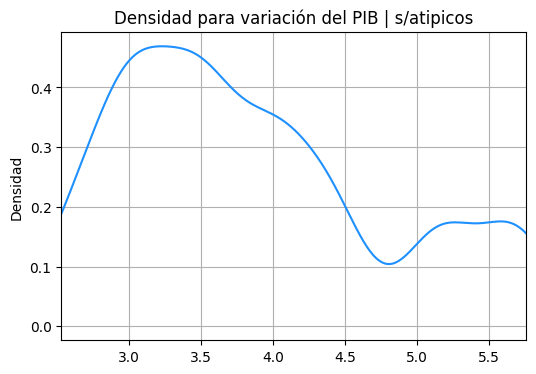

In [29]:
pib_mundial_sa.plot(
    kind = "density",
    y = "var_pib",
    figsize = [6,4],
    legend = None,
    title = "Densidad para variación del PIB | s/atipicos",
    color = "dodgerblue",
    grid = True,
    xlim = [pib_mundial_sa["var_pib"].min(), pib_mundial_sa["var_pib"].max()],
    bw_method = 0.25
)
plt.ylabel("Densidad")
plt.show()

<div class="alert alert-info">

El argumento `bw_method` es un controlador del nivel de detalle de un gráfico de densidad. Te sugiero que pruebas variar su valor probando las siguientes opciones y mirando lo que sucede con la visualización: `0.1`. `0.5`, `1.0` y `1.25`.

</div>

Tanto en el histograma como en la densidad, el punto más alto observado se corresponde con la medida central de los datos denominada moda, e igualmente es factible detectar el sesgo de la distribución visto que existen valores de variación en el PIB significativamente más altos que este punto medio, mientras que hacia el otro lado no se aprecia esta particularidad.  

A modo de complemento, genera un gráfico con la evolución a través de los años de la variación en el PIB promedio mundial (incluyendo los años atípicos). Esta visualización resulta importante especialmente cuando queremos estudiar el comportamiento de variables a través del tiempo, y profundizaremos en este estudio posteriormente cuando las tratemos como **Series Temporales**.

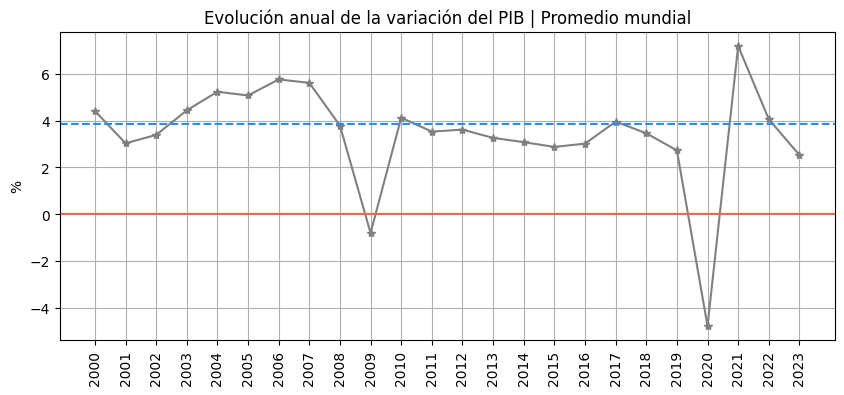

In [30]:
pib_mundial.plot(
    figsize = [10,4],
    legend = None,
    marker = "*",
    xticks = range(2000,2024),
    rot = 90,
    grid = True,
    title = "Evolución anual de la variación del PIB | Promedio mundial",
    xlabel = "",
    ylabel = "%",
    color = "gray"
)
plt.axhline(y = 0, color = "tomato")
plt.axhline(
    y = pib_mundial_sa["var_pib"].mean(), 
    color = "dodgerblue", 
    linestyle = "--"
)
plt.show()

Extrae conclusiones relevantes respecto al comportamiento observado del indicador.

<div class="alert alert-success">

**CONCLUSIONES**

| # | Conclusión |
| ---- | ---- |
| 1 | El promedio de variación del PIB mundial durante el nuevo siglo se ubica entre 3% y 4%, esto es, los estados han gozado en general de crecimiento y desarrollo económico. Sin embargo, se evidencia también una volatilidad significativa producto de eventos específicos. En concreto, la crisis *subprime* del año 2009 conllevó un deterioro a nivel mundial en cuanto al crecimiento y desarrollo económico. Así también, se evidencian efectos derivados de la pandemia del COVID en el año 2020, en el cual hubo una contracción de más de 4 puntos porcentuales respecto al promedio histórico. |

</div>

### ¿Qué variables inciden principalmente en los cambios a nivel de la variación en el PIB?

Antes de contestar esta pregunta, excluye del dataset consolidado los años 2009 y 2020 por ser especiales en cuanto a la situación mundial vivida durante esos períodos.

In [31]:
per_excluir = [2009,2020]
df_consolidado = df_consolidado.query("year != @per_excluir")

Estudia el grado de correlación existente entre las distintas métricas que tienes disponibles con el método `corr`. Visto que no conocemos si esta relación es lineal o no, incorpora el argumento `method = "spearman"`.

In [32]:
mat_corr = df_consolidado[["var_pib","ahorro","var_pob","pct_urbana"]].corr(method = "spearman")
print(mat_corr.round(4))

            var_pib  ahorro  var_pob  pct_urbana
var_pib      1.0000  0.1456   0.1384     -0.2207
ahorro       0.1456  1.0000  -0.0299      0.2235
var_pob      0.1384 -0.0299   1.0000     -0.2725
pct_urbana  -0.2207  0.2235  -0.2725      1.0000


Recuerda que la correlación mide el grado de vinculación entre un par de variables, tal que:

* Si su valor es cercano a -1, se dice que ambas variables mantienen una relación **inversamente proporcional**, esto es, cuando una se incrementa la otra disminuye.

* Si su valor es cercano a +1, se dice que ambas variables mantienen una relación **directamente proporcional**, esto es, cuando una se incrementa la otra igualmente aumenta.

* Si su valor es cercano a 0, se dice que ambas variables no tienen relación estadística alguna.

<div class="alert alert-info">

Una relación lineal entre dos variables $x$ e $y$ existe si es que se cumple que

$$ y = f(x) \approx w_0 + w_1\times x $$

donde $w_0$ y $w_1$ son pesos o coeficientes constantes.

Si tenemos evidencia que existe este tipo de relación entonces el método de correlación a utilizar es el de *pearson*. Te sugiero que investigues sobre la diferencia existente entre el usado en este caso y el mencionado de Pearson.

</div>

Ante esto, repite el cálculo pero ahora utiliza los promedios anuales de cada indicador a fin de "diluir" los efectos exógenos de cada país que pueden estar alterando los niveles del estadístico. Igualmente excluye los casos atípicos definidos en la pregunta anterior.

In [33]:
# Agregar datos por año
prom_anuales = df_consolidado.groupby("year")[["var_pib","ahorro","var_pob","pct_urbana"]].mean()
prom_anuales_sa = prom_anuales.query("var_pib >= @umbral_inf and var_pib <= @umbral_sup")

# Calcular matriz de correlacion
mat_corr = prom_anuales_sa[["var_pib","ahorro","var_pob","pct_urbana"]].corr(method = "spearman")
print(mat_corr.round(4))

            var_pib  ahorro  var_pob  pct_urbana
var_pib      1.0000  0.5364   0.2662     -0.5286
ahorro       0.5364  1.0000   0.0299      0.1961
var_pob      0.2662  0.0299   1.0000     -0.4779
pct_urbana  -0.5286  0.1961  -0.4779      1.0000


Si solamente nos enfocamos en los niveles de correlación asociados a la variación en el PIB podemos notar que existe cierto grado de incidencia positivo de este indicador con el nivel de ahorro. También existe una relación de incidencia negativa con el porcentaje de población urbana. 

Visualiza entonces la relación existente entre ahorro y var_pib mediante una gráfica de dispersión. Incluye una línea de ajuste simple con la función `np.polyfit`.

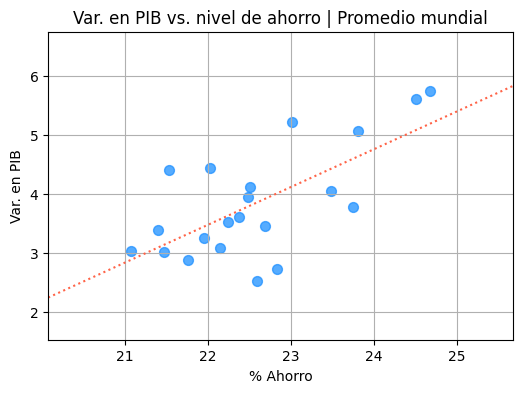

In [34]:
# Generar linea de ajuste simple
lin_fit = np.polyfit(
    x = prom_anuales_sa["ahorro"], 
    y = prom_anuales_sa["var_pib"], 
    deg = 1
)

# Generar gráfico de dispersion
prom_anuales_sa.plot(
    kind = "scatter",
    x = "ahorro",
    y = "var_pib",
    figsize = [6,4],
    color = "dodgerblue",
    alpha = 0.75,
    grid = True,
    s = 50,
    title = "Var. en PIB vs. nivel de ahorro | Promedio mundial",
    xlabel = "% Ahorro",
    ylabel = "Var. en PIB",
    xlim = [prom_anuales_sa["ahorro"].min() - 1, prom_anuales_sa["ahorro"].max() + 1],
    ylim = [prom_anuales_sa["var_pib"].min() - 1, prom_anuales_sa["var_pib"].max() + 1]
)
plt.axline(xy1 = [0,lin_fit[1]], slope = lin_fit[0], color = "tomato", linestyle = ":")
plt.show()

Visualiza ahora la relación existente entre pct_urbana y var_pib mediante una gráfica de dispersión e igualmente incluye una línea de ajuste.

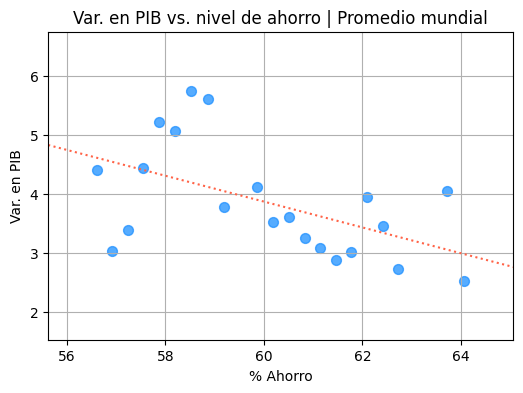

In [ ]:
# Generar linea de ajuste simple
lin_fit = np.polyfit(
    x = prom_anuales_sa["pct_urbana"], 
    y = prom_anuales_sa["var_pib"], 
    deg = 1
)

# Generar gráfico de dispersion
prom_anuales_sa.plot(
    kind = "scatter",
    x = "pct_urbana",
    y = "var_pib",
    figsize = [6,4],
    color = "dodgerblue",
    alpha = 0.75,
    grid = True,
    s = 50,
    title = "Var. en PIB vs. % de población urbana | Promedio mundial",
    xlabel = "% Poblacion urbana",
    ylabel = "Var. en PIB",
    xlim = [prom_anuales_sa["pct_urbana"].min() - 1, prom_anuales_sa["pct_urbana"].max() + 1],
    ylim = [prom_anuales_sa["var_pib"].min() - 1, prom_anuales_sa["var_pib"].max() + 1]
)
plt.axline(xy1 = [0,lin_fit[1]], slope = lin_fit[0], color = "tomato", linestyle = ":")
plt.show()

<div class="alert alert-info">

En estas secciones hemos empleado una estrategia de "suavizamiento" de nuestros datos mediante el uso del promedio de indicadores por año, lo que nos ha permitido evidenciar de mejor manera dinámicas y comportamientos de variables. Esta técnica será de mucha utilidad cuando estudies **Series Temporales** o apliques capas convolucionales en modelos predictivos con **Redes Neuronales**. 

</div>

<div class="alert alert-info">

Las correlaciones de Pearson y de Spearman que hemos empleado aquí son útiles para evaluar relaciones entre variables siempre que las mismas sean de tipo numérico. Sin embargo, no hacen sentido cuando queremos estudiar la dinámica entre datos de diferente tipo.

Te sugiero investigar qué otras medidas estadísticas pueden ser útiles en otras circunstancias.

</div>

Establece las conclusiones pertinentes de este análisis de correlación.

<div class="alert alert-success">

**CONCLUSIONES**

| # | Conclusión |
| ---- | ---- |
| 1 | Si bien a nivel de cada país no se evidencia que ningún indicador tiene una relación significativa con los cambios en el PIB (lo cual estaría asociado al grado de volatilidad observado por las diversas condiciones socioeconómicas y factores exógenos de cada estado), a nivel promedio se podría afirmar que un mayor ahorro de la población conlleva mejores niveles de crecimiento económico producto de una mayor capacidad financiera para la generación de capital y consumo futuro. |
| 2 | En esta línea, en el promedio mundial se evidencia una relación negativa entre el porcentaje de población urbana y variación en el PIB, lo cual da cuenta posiblemente de mayores potenciales de desarrollo en estados con alta incidencia agrícola y extractiva. Lo anterior no sugiere que países con estas características sean más desarrollados que su contraparte, sino que los cambios observados a nivel de PIB son más grandes en términos porcentuales. |

</div>

### ¿Qué tan probable es que un país tenga una recesión en un año cualquiera?

Crea una nueva columna en el dataset consolidado que sea de tipo booleano y que permita evidenciar aquellas observaciones en las que han existido recesiones. Para simplificar este concepto asumamos que una recesión es una variación negativa del PIB.

In [36]:
df_consolidado["es_recesion"] = df_consolidado["var_pib"].apply(lambda x: True if x < 0 else False)
df_consolidado["es_recesion"].value_counts()

es_recesion
False    2643
True      239
Name: count, dtype: int64

Calcula en cuántos casos del dataset han existido recesiones y guarda este resultado en una variable llamada `casos_exitosos`.

In [37]:
casos_exitosos = df_consolidado["es_recesion"].sum()
print(f"Observaciones con recesión: {casos_exitosos:,.0f}")

Observaciones con recesión: 239


Guarda la totalidad de casos posibles en la variable `casos_totales`.

In [38]:
casos_totales = df_consolidado["es_recesion"].count()
print(f"Observaciones totales: {casos_totales:,.0f}")

Observaciones totales: 2,882


Calcula la probabilidad de que en un año cualquiera un país se encuentre en recesión. Recuerda que una probabilidad se mide como la razón entre los casos de éxito (eventos en los que sucede algo que estamos queriendo medir) y los casos totales observados. 

In [39]:
prob_recesion = casos_exitosos / casos_totales
print(f"La probabilidad que un país tenga una recesión en un año cualquiera es de: {prob_recesion:.1%}")

La probabilidad que un país tenga una recesión en un año cualquiera es de: 8.3%


La probabilidad es una medida que nos ayuda a estimar cuantitativamente la incertidumbre asociada a eventos que suceden en el mundo real. La misma debe cumplir SIEMPRE estas tres condiciones:

* Ser cero o positiva, es decir, todo evento *puede* suceder.

* Ser menor o igual a 1, es decir, potencialmente existen otros eventos *posibles* y complementarios.

* La suma de todas las probabilidades de eventos posibles en un contexto es igual a 1, es decir, alguno *debe* suceder.


<div class="alert alert-info">

Vale que notes que esta probabilidad obtenida podría calcularse de forma directa con el siguiente código:

```py
prob_recesion = df_consolidado["es_recesion"].mean()
```

Piensa el porqué esto funciona.

</div>

Para complementar este resultado, encuentra el top 10 de países con una mayor probabilidad de recesión. Para esto, vuelve a repetir este cálculo agregando la información por país.

In [40]:
# Obtener probabilidad de recesión por pais
rec_por_pais = (
    df_consolidado
    .groupby("country_name")
    .agg(prob_recesion = ("es_recesion","mean"))
    .sort_values(by = "prob_recesion", ascending = False)
)

# Extraer 10 paises con mayor probabilidad
print("TOP 10 PAISES CON MAYOR PROBABILIDAD DE RECESIÓN")
print(round(rec_por_pais.head(10) * 100,1))

TOP 10 PAISES CON MAYOR PROBABILIDAD DE RECESIÓN
                      prob_recesion
country_name                       
Libia                          45.5
Argentina                      40.9
Brunei Darussalam              31.8
Grecia                         31.8
Haiti                          31.8
Sudan                          31.8
Aruba                          31.8
Gambia                         22.7
Paraguay                       22.7
Congo, Republica del           22.7


Identifica igualmente el porcentaje de países que han presentado recesiones en este periodo de tiempo.

In [41]:
# Contar paises con recesion
paises_con_recesion = len(rec_por_pais.query("prob_recesion > 0"))

# Contar total de paises
paises_totales = len(rec_por_pais)
print(f"Porcentaje de paises con alguna recesion registrada: {paises_con_recesion / paises_totales:.1%}")

Porcentaje de paises con alguna recesion registrada: 61.1%


<div class="alert alert-success">

**CONCLUSIONES**

| # | Conclusión |
| ---- | ---- |
| 1 | En promedio, un año malo en términos económicos para un país cualquiera puede presentarse aproximadamente una vez por cada 12 años. En consecuencia se pueden esperar ciclos de alrededor de 10 a 11 años de crecimiento sostenido en las economías nacionales, ante lo cual las políticas de desarrollo e inversión pública y privada deberían alinearse a esta realidad observada para así garantizar que las variaciones positivas en el PIB sean las máximas posibles en estos años. |
| 2 | Entre los 10 países con mayor probabilidad de recesión resaltan, aquellos en donde han existido situaciones graves en términos económicos, sociales o políticos. Por ejemplo en Libia existe una grave crisis humanitaria desde el año 2011, en Argentina se han presentado períodos de deterioro económico especialmente a principios de la década del 2000. Lo expuesto ratifica lo mencionado en cuanto al impacto de factores externos en la variación del PIB. |
| 3 | Las recesiones en este siglo son un escenario bastante común, lo anterior queda evidenciado en el hecho que aproximadamente 60% de los países las han tenido. Es recomendable por tanto, que el Banco Mundial amplíe su espectro de apoyo a países exigiendo como garantías el cumplimiento de políticas de desarrollo. |

</div>

### ¿Existen diferencias en el crecimiento de países de "bajo desarrollo" frente a países de "alto desarrollo"?

Escoge 10 países que personalmente consideres de bajo desarrollo (i.e Ecuador, Bolivia, Guatemala, etc.), y 10 que consideres de alto desarrollo (i.e Estados Unidos, Alemania, Japón, etc.). Filtra el dataset de forma que solamente conserves estos países y adiciona una nueva columna que distinga a los dos grupos.  

In [42]:
# Seleccionar paises de alto y bajo desarrollo
bajo_desarrollo = ["Ecuador", "Bolivia", "Guatemala", "Madagascar", "Nepal", "Niger", "Nicaragua", "Burundi", "Mali", "Haiti"]
alto_desarrollo = ["Estados Unidos", "Alemania", "Japon", "Francia", "Canada", "Noruega", "Australia", "Singapur", "Dinamarca", "Suiza"]
paises_seleccionados = alto_desarrollo.copy()
paises_seleccionados.extend(bajo_desarrollo)

# Filtrar dataset con paises seleccionados
df_filtrado = df_consolidado.query("country_name in @paises_seleccionados")

# Adicionar columna con grupos de paises
df_filtrado["nivel_desarrollo"] = df_filtrado["country_name"].apply(lambda x: "Alto" if x in alto_desarrollo else "Bajo")
df_filtrado[["nivel_desarrollo","country_name"]].value_counts().reset_index().sort_values(by = "nivel_desarrollo")

,nivel_desarrollo,country_name,count
0,Alto,Alemania,22
8,Alto,Singapur,22
7,Alto,Noruega,22
6,Alto,Japon,22
5,Alto,Francia,22
9,Alto,Suiza,22
3,Alto,Dinamarca,22
2,Alto,Canada,22
1,Alto,Australia,22
4,Alto,Estados Unidos,22


Estudia comparativamente la distribución de var_pib en los países de alto y bajo desarrollo.

In [43]:
# Extraer muestra de valores de paises de alto desarrollo
vpib_alto = df_filtrado.query("nivel_desarrollo == 'Alto'")["var_pib"]
vpib_bajo = df_filtrado.query("nivel_desarrollo == 'Bajo'")["var_pib"]

# Generar resumen estadistico para ambos grupos
res_estadistico = pd.concat([vpib_alto.describe(), vpib_bajo.describe()], axis = 1)
res_estadistico.columns = ["Alto","Bajo"]
res_estadistico.round(2)

,Alto,Bajo
count,220.00,220.00
mean,2.45,3.77
std,1.95,2.92
min,-1.22,-12.41
25%,1.17,2.50
50%,2.22,4.10
75%,3.09,5.24
max,14.52,15.38


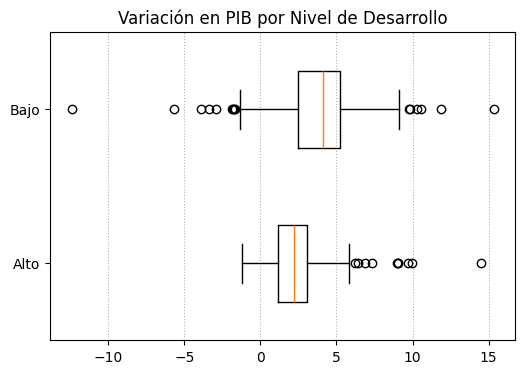

In [44]:
# Visualizar distribuciones con cajones
plt.figure(figsize = [6,4])
plt.boxplot([vpib_alto, vpib_bajo], vert = False, widths = 0.5)
plt.yticks(ticks = [1,2], labels = ["Alto","Bajo"])
plt.grid(axis = "x", linestyle = ":")
plt.title("Variación en PIB por Nivel de Desarrollo")
plt.show()

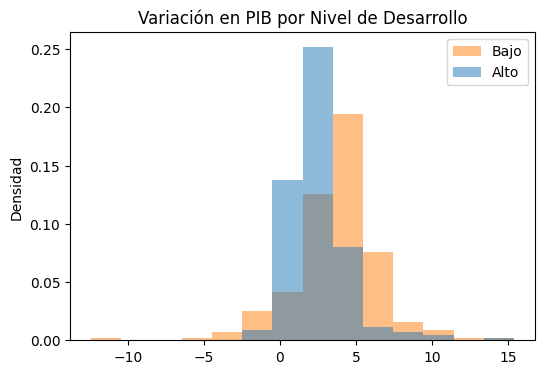

In [45]:
# Visualizar distribuciones con histogramas
plt.figure(figsize = [6,4])
plt.hist(
    [vpib_alto, vpib_bajo], 
    bins = int(np.sqrt(len(vpib_alto))), 
    density = True, 
    histtype = "stepfilled", 
    alpha = 0.5
)
plt.title("Variación en PIB por Nivel de Desarrollo")
plt.ylabel("Densidad")
plt.legend(["Bajo","Alto"])
plt.show()

Los resultados aquí alcanzados parecerían indicar que en promedio la variación del PIB en países de bajo desarrollo es mayor a aquella de los países de alto desarrollo. 

¿Cómo podemos estar completamente seguros de esta afirmación? La respuesta radica en la **Inferencia estadística**, cuyas técnicas nos permiten verificar hipótesis de forma objetiva y robusta. En el siguiente capítulo aprenderemos cómo hacer este tipo de pruebas.

Por ahora extrae conclusiones relevantes de este análisis descriptivo.

<div class="alert alert-success">

**CONCLUSIONES**

| # | Conclusión |
| ---- | ---- |
| 1 | Los países de bajo desarrollo tienden a crecer porcentualmente más que los países más desarrollados. Esto en principio podría resultar contraintuitivo pero se explica por el hecho que incrementar 1 punto porcentual de una base menor es, por decirlo de alguna manera, "más sencillo" que hacerlo de una base mayor. Aquí un ejemplo puramente ilustrativo: *Sea USD 100 M el PIB de un país de bajo desarrollo en un año cualquiera, y USD 1,000 M el de un pais de alto desarrollo. Incrementar 1% para el primer caso implica una variación absoluta de apenas USD 1 millón, mientras que para el segundo sería USD 10 millones. ¡Mucho más!* |

</div> 

<div class="alert alert-info">

Como has podido evidenciar, saber estadística te ayudará mucho en tu camino como analista o científico de datos. Te recomiendo por tanto que escuches y mires esta lista de reproducción sobre <a href="https://youtube.com/playlist?list=PLblh5JKOoLUK0FLuzwntyYI10UQFUhsY9&si=fTrXd4SYsSvR_iVe">Fundamentos de Estadística</a> creado por el canal **StatQuest de Josh Starmer**. Siéntete libre de seguir este canal para que puedas estar al tanto de todo su contenido.

</div>

